# Ví dụ Luồng Xử Lý & Inference Trên 1 Ảnh Duy Nhất

Notebook này minh họa luồng đi của **1 ảnh** trong project `uth-cv-coursework` (chỉ dùng cho trực quan hóa/EDA, mọi logic lõi gọi trực tiếp từ `src/`):
1. **Đầu vào:** Chọn 1 ảnh khuôn mặt (ví dụ 1 ảnh giả `sd_img2img` trong `data/synthetic/`).
2. **Lọc chất lượng (Curation Gate):** Kiểm tra độ nét (`compute_laplacian_sharpness`) và phát hiện khuôn mặt (`opencv_haar`) qua `ImageCurationGate`.
3. **Inference phát hiện Deepfake:** Chấm điểm xác suất `P(fake)` bằng `infer_pipeline` (`DeepfakeImageDetector` với checkpoint thật `active_learning_m3_best.pt`).
4. **Trực quan hóa:** Hiển thị ảnh cùng toàn bộ chỉ số lọc và kết quả dự đoán.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

# Định vị thư mục gốc của project
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common.seed import seed_everything
from src.pipelines.curate_image_dataset import ImageCurationGate
from src.pipelines.infer import infer_pipeline

seed_everything(42)
print(f"Project root: {ROOT}")

Project root: /home/bush/Projects/uth-cv-coursework


In [2]:
# 1. Chọn 1 ảnh đầu vào (có thể đổi sang ảnh thật trong data/raw/faces/ffhq/00000.png)
IMAGE_PATH = ROOT / "data/synthetic/d0_train_images/img2img/fake_ffhq_00000_0.png"
CHECKPOINT_PATH = ROOT / "experiments/checkpoints/active_learning_m3_best.pt"
CONFIG_PATH = ROOT / "configs/config.yaml"

assert IMAGE_PATH.is_file(), f"Không tìm thấy ảnh: {IMAGE_PATH}"
assert CHECKPOINT_PATH.is_file(), f"Không tìm thấy checkpoint: {CHECKPOINT_PATH}"

# Đọc ảnh ở hệ màu RGB (H, W, C) -> chuyển sang Tensor (C, H, W) trong khoảng [0.0, 1.0]
with Image.open(IMAGE_PATH) as im:
    rgb_img = im.convert("RGB")
    rgb_np = np.array(rgb_img, dtype=np.float32) / 255.0  # (H, W, C)

img_tensor = torch.from_numpy(rgb_np).permute(2, 0, 1)  # (C, H, W) = (3, H, W)
print(f"Ảnh: {IMAGE_PATH.relative_to(ROOT)} | Shape (C, H, W): {tuple(img_tensor.shape)}")

Ảnh: data/synthetic/d0_train_images/img2img/fake_ffhq_00000_0.png | Shape (C, H, W): (3, 512, 512)


In [3]:
# 2. Đánh giá qua bộ lọc chất lượng (Curation Gate)
gate = ImageCurationGate(
    min_sharpness=10.0,
    clip_enabled=False,
    face_backend="opencv_haar",
    dedup=False,
)

curation_report = gate.evaluate_image(
    image=img_tensor,
    image_id=IMAGE_PATH.stem,
)

print("=== KẾT QUẢ BỘ LỌC CURATION GATE ===")
print(f"- Đạt chuẩn (is_valid): {curation_report.is_valid}")
print(f"- Độ nét (Laplacian sharpness): {curation_report.sharpness_score:.2f}")
print(f"- Phát hiện khuôn mặt (face_detected): {curation_report.face_detected}")
print(f"- Lý do loại (nếu có): {curation_report.rejection_reasons}")

=== KẾT QUẢ BỘ LỌC CURATION GATE ===
- Đạt chuẩn (is_valid): False
- Độ nét (Laplacian sharpness): 5.99
- Phát hiện khuôn mặt (face_detected): True
- Lý do loại (nếu có): ['Sharpness 5.99 below threshold 10.00']


In [4]:
# 3. Inference phát hiện Deepfake bằng dinoViT (model.eval + torch.no_grad + autocast bên trong infer_pipeline)
infer_results = infer_pipeline(
    config_path=str(CONFIG_PATH),
    input_path=str(IMAGE_PATH),
    checkpoint_path=str(CHECKPOINT_PATH),
    threshold=0.50,
)
pred = infer_results[0]

print("=== KẾT QUẢ INFERENCE DETECTOR ===")
print(f"- Xác suất giả P(fake): {pred['p_fake']:.4f}")
print(f"- Nhãn dự đoán (@ tau=0.50): {pred['prediction'].upper()}")

/home/bush/Projects/uth-cv-coursework/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-25 18:37:25] [INFO] [src.models.detector.image_detector]: Initialized DeepfakeImageDetector: backbone=dinov2_small, classes=1, frozen=False
[2026-11-25 18:37:27] [INFO] [infer_pipeline]: Inference [fake_ffhq_00000_0.png] -> P(fake)=1.0000 (fake @ tau=0.50)
=== KẾT QUẢ INFERENCE DETECTOR ===
- Xác suất giả P(fake): 1.0000
- Nhãn dự đoán (@ tau=0.50): FAKE


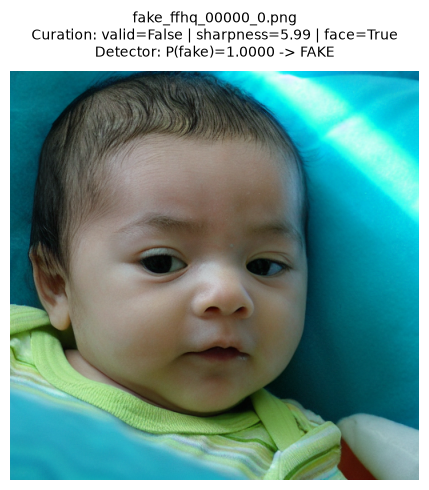

In [5]:
# 4. Trực quan hóa ảnh cùng toàn bộ số liệu
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(rgb_img)
ax.axis("off")
title = (
    f"{IMAGE_PATH.name}\n"
    f"Curation: valid={curation_report.is_valid} | "
    f"sharpness={curation_report.sharpness_score:.2f} | "
    f"face={curation_report.face_detected}\n"
    f"Detector: P(fake)={pred['p_fake']:.4f} -> {pred['prediction'].upper()}"
)
ax.set_title(title, fontsize=10, pad=10)
plt.tight_layout()
plt.show()